In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict
from dotenv import load_dotenv

In [2]:
load_dotenv()

True

In [3]:
model = ChatGroq(model='openai/gpt-oss-20b')

In [4]:
class BlogState(TypedDict):

    title: str
    outline: str
    content: str

In [6]:
def create_outline(state: BlogState) -> BlogState:

    #fetch title
    title = state['title']

    #call llm gen outline
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = model.invoke(prompt).content

    #update state
    state['outline'] = outline

    return state


In [7]:
def create_blog(state: BlogState) -> BlogState:

    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the following outline \n {outline}'

    content = model.invoke(prompt).content
    state['content'] = content
    return state

In [10]:
graph = StateGraph(BlogState)
graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)

workflow = graph.compile()

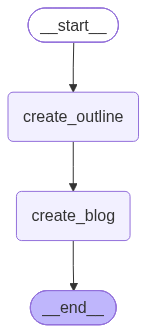

In [11]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [12]:
initial_state = {'title': 'Rise of Daft Punk'}

final_state = workflow.invoke(initial_state)

print(final_state)

{'title': 'Rise of Daft Punk', 'outline': '## Blog Outline: **The Rise of Daft\u202fPunk – From Garage Beats to Global Icons**\n\n| Section | Sub‑sections | Key Points / Questions |\n|--------|--------------|------------------------|\n| **1. Hook & Thesis** | • 30‑second teaser video/playlist <br>• One‑sentence thesis | *Why Daft\u202fPunk’s ascent matters for electronic music, pop culture, and the future of the industry.* |\n| **2. Setting the Stage** | 2.1. The 90s French club scene <br>2.2. The emergence of French house | • Paris, Marseille, and the “French Touch” <br>• Influence of Gilles Peterson, David Guetta, and the club “Le Bataclan” |\n| **3. The Founding Story** | 3.1. Thomas Bangalter & Guy-Manuel de Homem‑Cere (BMC) <br>3.2. Early experiments & the garage‑house sound | • Childhood influences (James Brown, The Clash, Kraftwerk) <br>• The decision to adopt a futuristic, mask‑wearing aesthetic |\n| **4. The First Breakthrough – *Homework* (1997)** | 4.1. Production process & 

In [13]:
print(final_state['outline'])

## Blog Outline: **The Rise of Daft Punk – From Garage Beats to Global Icons**

| Section | Sub‑sections | Key Points / Questions |
|--------|--------------|------------------------|
| **1. Hook & Thesis** | • 30‑second teaser video/playlist <br>• One‑sentence thesis | *Why Daft Punk’s ascent matters for electronic music, pop culture, and the future of the industry.* |
| **2. Setting the Stage** | 2.1. The 90s French club scene <br>2.2. The emergence of French house | • Paris, Marseille, and the “French Touch” <br>• Influence of Gilles Peterson, David Guetta, and the club “Le Bataclan” |
| **3. The Founding Story** | 3.1. Thomas Bangalter & Guy-Manuel de Homem‑Cere (BMC) <br>3.2. Early experiments & the garage‑house sound | • Childhood influences (James Brown, The Clash, Kraftwerk) <br>• The decision to adopt a futuristic, mask‑wearing aesthetic |
| **4. The First Breakthrough – *Homework* (1997)** | 4.1. Production process & DIY ethos <br>4.2. Key tracks (Around the World, Da Funk) <b

In [14]:
print(final_state['content'])

# The Rise of Daft Punk – From Garage Beats to Global Icons  

> *“We’re all robots in the end.” – Daft Punk (2021)*  

---

## 1. Hook & Thesis  

### 🎬 30‑second Teaser  
> **[Watch the 30‑second montage here →]**  
> (A fast‑cut clip of “One More Time” crowd‑sweeping dance, the neon‑lit *Tron: Legacy* opening, and the 2021 “Epilogue” finale.)

> **Thesis:** *Daft Punk’s meteoric rise exemplifies how a blend of musical innovation, visual storytelling, and brand mystique can redefine an entire genre and influence global pop culture.*

---

## 2. Setting the Stage  

| Sub‑section | Key Points |
|-------------|------------|
| **2.1 The 90s French Club Scene** | Paris’s *Le Bataclan*, Marseille’s underground raves, the rise of the “French Touch” label. |
| **2.2 Emergence of French House** | Gilles Peterson’s BBC radio show, David Guetta’s early club mixes, the “French Touch” aesthetic that blended disco, funk, and house. |

- **Paris & Marseille** were the crucibles where electronic mu